In [3]:
import sys
print(sys.executable)

c:\Users\vrajain\OneDrive - Capgemini\Desktop\Food\venv\Scripts\python.exe


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

#Load Dataset
zomato = pd.read_csv("../data/zomato.csv")

#Check Dataset Size
print(zomato.shape)

#View First 5 Rows
zomato.head()


(51717, 17)


,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


In [6]:
#Check Data Types
zomato.info()

<class 'pandas.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   url                          51717 non-null  str  
 1   address                      51717 non-null  str  
 2   name                         51717 non-null  str  
 3   online_order                 51717 non-null  str  
 4   book_table                   51717 non-null  str  
 5   rate                         43942 non-null  str  
 6   votes                        51717 non-null  int64
 7   phone                        50509 non-null  str  
 8   location                     51696 non-null  str  
 9   rest_type                    51490 non-null  str  
 10  dish_liked                   23639 non-null  str  
 11  cuisines                     51672 non-null  str  
 12  approx_cost(for two people)  51371 non-null  str  
 13  reviews_list                 51717 non-null  str  
 14  m

In [7]:
zomato.columns.tolist()

['url',
 'address',
 'name',
 'online_order',
 'book_table',
 'rate',
 'votes',
 'phone',
 'location',
 'rest_type',
 'dish_liked',
 'cuisines',
 'approx_cost(for two people)',
 'reviews_list',
 'menu_item',
 'listed_in(type)',
 'listed_in(city)']

In [8]:
zomato.isnull().sum().sort_values(ascending=False)

dish_liked                     28078
rate                            7775
phone                           1208
approx_cost(for two people)      346
rest_type                        227
cuisines                          45
location                          21
url                                0
address                            0
votes                              0
name                               0
online_order                       0
book_table                         0
reviews_list                       0
menu_item                          0
listed_in(type)                    0
listed_in(city)                    0
dtype: int64

In [9]:
print("Duplicate rows:", zomato.duplicated().sum())

Duplicate rows: 0


In [10]:
print("Rows and Columns:", zomato.shape)

Rows and Columns: (51717, 17)


In [11]:
zomato = zomato.drop(
    columns=[
        'url',
        'phone',
        'address'
    ]
)

zomato.shape

(51717, 14)

In [12]:
zomato['rate'].unique()[:20]

<StringArray>
['4.1/5', '3.8/5', '3.7/5', '3.6/5', '4.6/5', '4.0/5', '4.2/5', '3.9/5',
 '3.1/5', '3.0/5', '3.2/5', '3.3/5', '2.8/5', '4.4/5', '4.3/5',   'NEW',
 '2.9/5', '3.5/5',     nan, '2.6/5']
Length: 20, dtype: str

In [13]:
zomato['rate'] = zomato['rate'].astype(str)

zomato['rate'] = zomato['rate'].str.replace(
    '/5',
    '',
    regex=False
)

zomato['rate'] = zomato['rate'].replace(
    ['NEW', '-'],
    np.nan
)

zomato['rate'] = pd.to_numeric(
    zomato['rate'],
    errors='coerce'
)


In [14]:
zomato['rate'].describe()

count    41665.000000
mean         3.700449
std          0.440513
min          1.800000
25%          3.400000
50%          3.700000
75%          4.000000
max          4.900000
Name: rate, dtype: float64

In [15]:
# =========================
# DATA CLEANING
# =========================

import numpy as np

print("Original Shape:", zomato.shape)

# Remove duplicates
zomato.drop_duplicates(inplace=True)

# Remove rows with missing names
zomato.dropna(subset=["name"], inplace=True)

# Fill missing values

zomato["rate"] = zomato["rate"].fillna("0")
zomato["online_order"] = zomato["online_order"].fillna("No")
zomato["book_table"] = zomato["book_table"].fillna("No")
zomato["rest_type"] = zomato["rest_type"].fillna("Unknown")
zomato["cuisines"] = zomato["cuisines"].fillna("Unknown")
zomato["dish_liked"] = zomato["dish_liked"].fillna("Not Mentioned")

# Clean rate column

zomato["rate"] = (
    zomato["rate"]
    .astype(str)
    .str.replace("/5", "", regex=False)
    .str.replace("NEW", "0", regex=False)
    .str.replace("-", "0", regex=False)
)

zomato["rate"] = pd.to_numeric(
    zomato["rate"],
    errors="coerce"
)

# Clean cost column

zomato["approx_cost(for two people)"] = (
    zomato["approx_cost(for two people)"]
    .astype(str)
    .str.replace(",", "", regex=False)
)

zomato["approx_cost(for two people)"] = pd.to_numeric(
    zomato["approx_cost(for two people)"],
    errors="coerce"
)

# Clean votes

zomato["votes"] = pd.to_numeric(
    zomato["votes"],
    errors="coerce"
)

# Drop rows with missing key values

zomato.dropna(
    subset=[
        "rate",
        "votes",
        "approx_cost(for two people)"
    ],
    inplace=True
)

# Reset index

zomato.reset_index(
    drop=True,
    inplace=True
)

print("Cleaned Shape:", zomato.shape)

print("\nMissing Values Remaining:")
print(zomato.isnull().sum().sort_values(ascending=False))

print("\nData Types:")
print(zomato.dtypes)

Original Shape: (51717, 14)
Cleaned Shape: (51309, 14)

Missing Values Remaining:
name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
location                       0
rest_type                      0
dish_liked                     0
cuisines                       0
approx_cost(for two people)    0
reviews_list                   0
menu_item                      0
listed_in(type)                0
listed_in(city)                0
dtype: int64

Data Types:
name                               str
online_order                       str
book_table                         str
rate                           float64
votes                            int64
location                           str
rest_type                          str
dish_liked                         str
cuisines                           str
approx_cost(for two people)    float64
reviews_list                       str
m

In [16]:
print("Rows:", zomato.shape[0])
print("Columns:", zomato.shape[1])

print("\nMissing Values")
display(
    zomato.isnull()
    .sum()
    .sort_values(ascending=False)
)

print("\nDuplicates:", zomato.duplicated().sum())

Rows: 51309
Columns: 14

Missing Values


name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
location                       0
rest_type                      0
dish_liked                     0
cuisines                       0
approx_cost(for two people)    0
reviews_list                   0
menu_item                      0
listed_in(type)                0
listed_in(city)                0
dtype: int64


Duplicates: 0


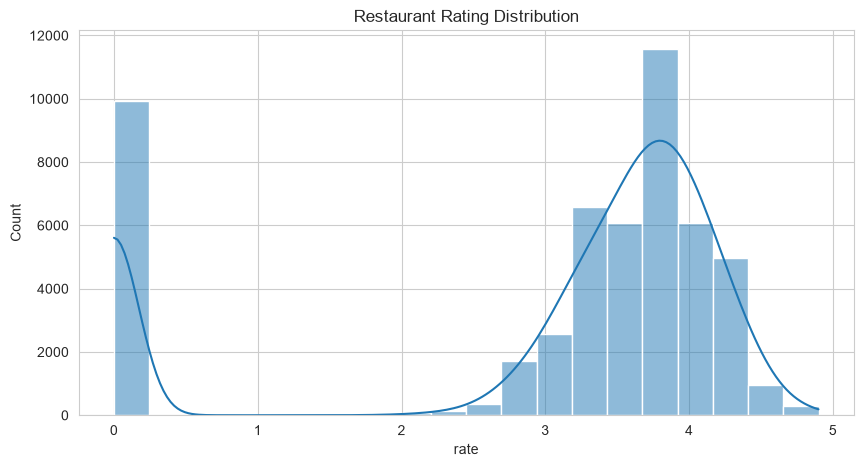

In [22]:
# Rating Distribution
plt.figure(figsize=(10,5))

sns.histplot(
    zomato['rate'],
    bins=20,
    kde=True
)

plt.title("Restaurant Rating Distribution")
plt.show()

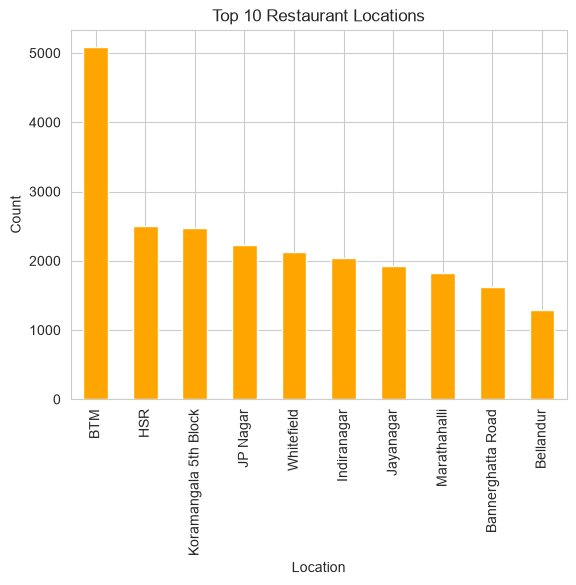

In [23]:
# Top 10 Locations

top_locations = (
    zomato['location']
    .value_counts()
    .head(10)
)

top_locations.plot(
    kind='bar',
    color='orange'
)

plt.title("Top 10 Restaurant Locations")
plt.xlabel("Location")
plt.ylabel("Count")

plt.show()

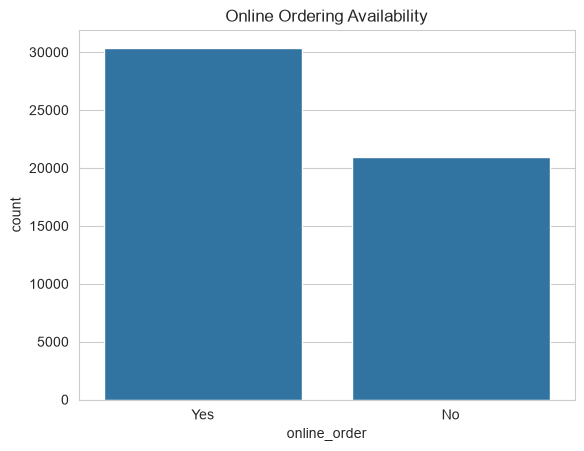

In [19]:
sns.countplot(
    x="online_order",
    data=zomato
)

plt.title("Online Ordering Availability")

plt.show()

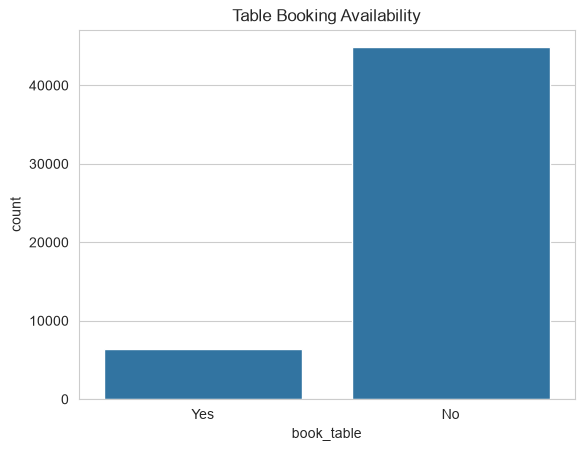

In [24]:
sns.countplot(
    x='book_table',
    data=zomato
)

plt.title("Table Booking Availability")
plt.show()


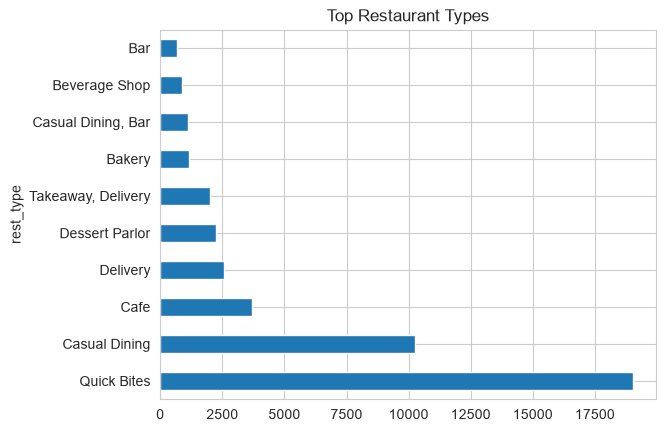

In [26]:
#Top Restaurant Types

zomato['rest_type'] \
.value_counts() \
.head(10) \
.plot(kind='barh')

plt.title("Top Restaurant Types")
plt.show()

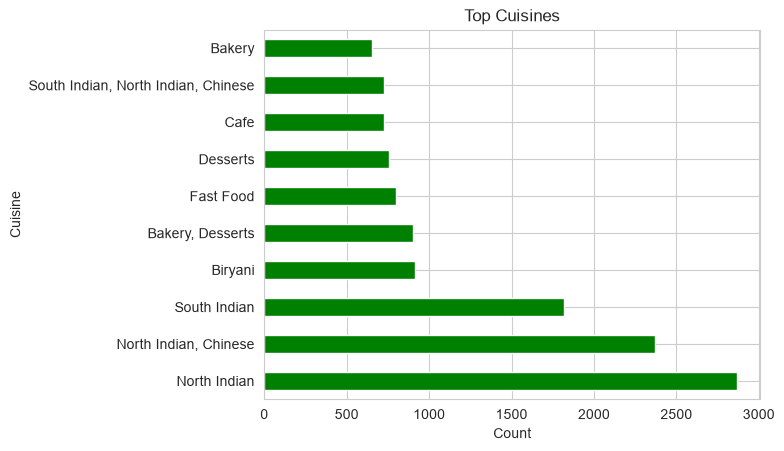

In [27]:
#Top Cuisines

zomato['cuisines'] \
.value_counts() \
.head(10) \
.plot(kind='barh',
      color='green')

plt.title("Top Cuisines")
plt.xlabel("Count")
plt.ylabel("Cuisine")
plt.show()

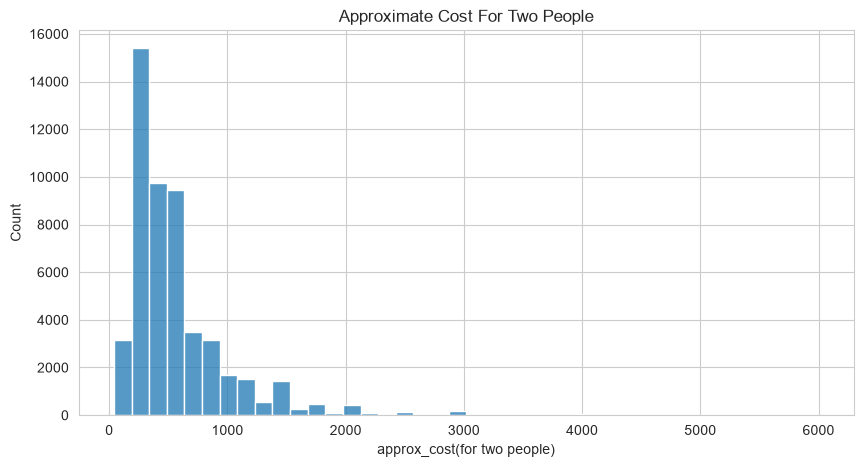

In [28]:
# Cost Distribution

plt.figure(figsize=(10,5))

sns.histplot(
    zomato['approx_cost(for two people)'],
    bins=40
)

plt.title("Approximate Cost For Two People")
plt.show()

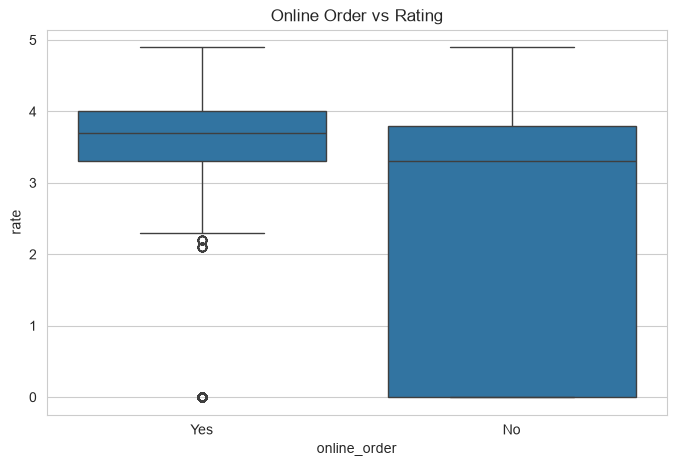

In [29]:
# Online Order vs Rating

plt.figure(figsize=(8,5))

sns.boxplot(
    x='online_order',
    y='rate',
    data=zomato
)

plt.title("Online Order vs Rating")
plt.show()

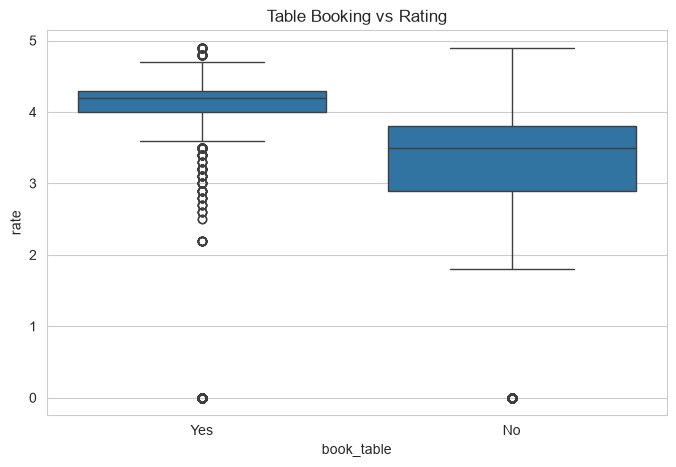

In [30]:
# Table Booking vs Rating

plt.figure(figsize=(8,5))

sns.boxplot(
    x='book_table',
    y='rate',
    data=zomato
)

plt.title("Table Booking vs Rating")
plt.show()

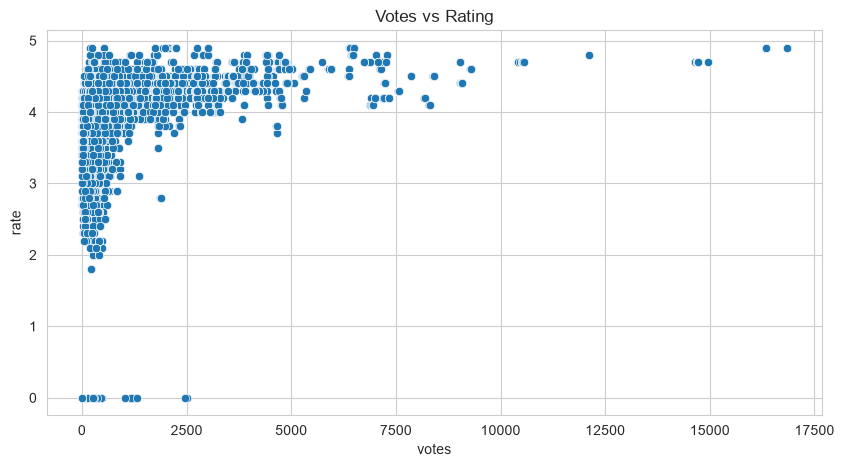

In [31]:
# Votes vs Rating

plt.figure(figsize=(10,5))

sns.scatterplot(
    x='votes',
    y='rate',
    data=zomato
)

plt.title("Votes vs Rating")
plt.show()

In [32]:
# Top Rated Restaurants

top_rated = (
    zomato.groupby('name')['rate']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

top_rated

name
SantÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂ© Spa Cuisine    4.900000
Asia Kitchen By Mainland China                                                      4.900000
Byg Brewski Brewing Company                                                         4.900000
Punjab Grill                                                                        4.871429
Belgian Waffle Factory                                                              4.844828
O.G. Variar & Sons                                                                  4.800000
The Pizza Bakery                                                                    4.800000
Flechazo                                                                            4.800000
AB's - Absolute Barbecues                                                           4.789474
CTR                                                                                 4.750000
Name: rate, dtype: float64

Text(0.5, 1.0, 'Most Popular')

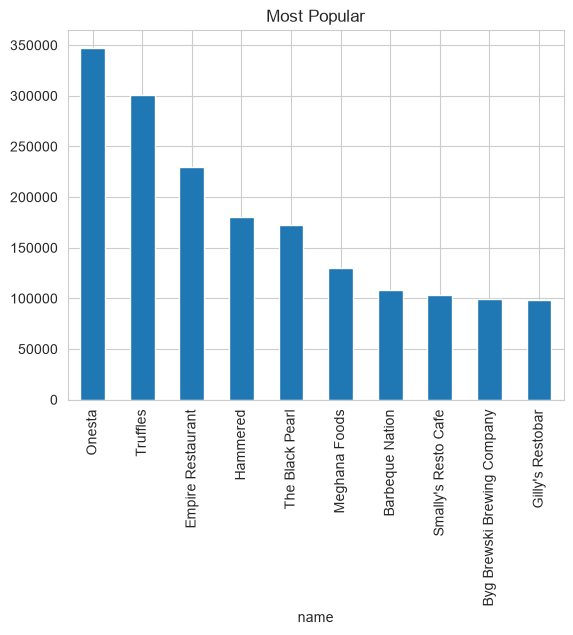

In [33]:
# Most Popular Restaurants

popular = (
    zomato.groupby('name')['votes']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

popular.plot(kind='bar')

plt.title("Most Popular")

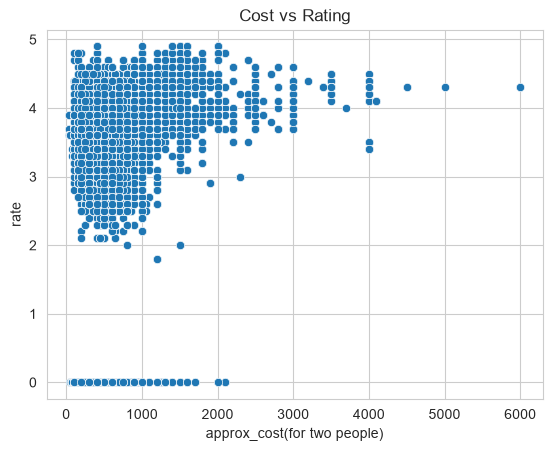

In [34]:
# Cost vs Rating

sns.scatterplot(
    x='approx_cost(for two people)',
    y='rate',
    data=zomato
)

plt.title("Cost vs Rating")
plt.show()

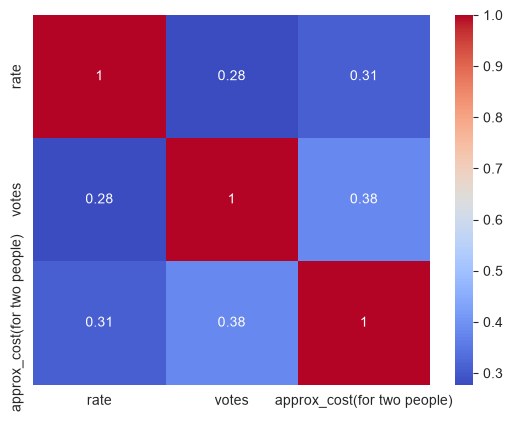

In [35]:
#  Correlation

corr = zomato[
    ['rate',
     'votes',
     'approx_cost(for two people)']
].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)

plt.show()

In [37]:
# Business Insights

print("Average Rating:")
print(zomato['rate'].mean())

print("\nAverage Cost For Two:")
print(zomato['approx_cost(for two people)'].mean())

print("\nTop Location:")
print(zomato['location'].mode()[0])

print("\nMost Popular Cuisine:")
print(zomato['cuisines'].mode()[0])

print("\nTotal Restaurants:")
print(zomato['name'].nunique())

Average Rating:
2.984417938373385

Average Cost For Two:
555.5326550897504

Top Location:
BTM

Most Popular Cuisine:
North Indian

Total Restaurants:
8756


In [38]:
zomato.to_csv(
    "../data/cleaned_zomato.csv",
    index=False
)

print("cleaned_zomato.csv saved successfully")

cleaned_zomato.csv saved successfully
